# Quickstart: evaluating active learning on a multi-output stream

This notebook walks through fishladder's main pieces using River for the data, the model and the
metrics:

1. a multi-output stream where each output has a different labelling cost,
2. a query strategy and a budget manager deciding which outputs to ask for,
3. prequential evaluation, which produces a tidy experiment log,
4. metrics and learning curves computed from that log, indexed by cost.

In [1]:
import matplotlib.pyplot as plt
from river import datasets, linear_model, metrics, multioutput, preprocessing, utils

import fishladder as fl

## A multi-output stream

fishladder takes any iterable of `(x, y)` pairs where `y` is a dictionary of outputs, which is
River's format. Here we derive three outputs from the features of River's `Friedman` generator.
Think of them as three quantities of an industrial process, measured with increasingly expensive
lab analyses.

In [2]:
OUTPUTS = ["temperature", "pressure", "purity"]
COSTS = {"temperature": 1.0, "pressure": 2.0, "purity": 5.0}


def process_stream(n, seed=42):
    for x, y in datasets.synth.Friedman(seed=seed).take(n):
        yield (
            x,
            {
                "temperature": y,
                "pressure": 10 * x[3] + 5 * x[4],
                "purity": 20 * x[0] * x[1],
            },
        )


x, y = next(process_stream(1))
y

{'temperature': 7.6612066799391085,
 'pressure': 5.91446345230829,
 'purity': 0.3198509427808743}

## Model, strategy and budget

The model is a regular River multi-output model. River's multi-output models accept a `y` that
contains only some of the outputs, which is exactly what happens when only some outputs are
queried, so no adapter is needed.

The strategy scores each output, and the budget manager decides what is affordable. Budgets are
measured in cost, not in number of queries: `RateBudget(1.5)` makes 1.5 cost units available per
instance, carrying over what is not spent.

In [3]:
def make_model():
    return multioutput.RegressorChain(
        preprocessing.StandardScaler() | linear_model.LinearRegression(), order=OUTPUTS
    )


metric = metrics.multioutput.PerOutput(metrics.MAE())

log = fl.evaluate.prequential(
    dataset=process_stream(2000),
    model=make_model(),
    strategy=fl.strategy.RandomPerOutput(p=0.3, seed=42),
    budget=fl.budget.RateBudget(1.5),
    costs=COSTS,
    metric=metric,
)
metric

temperature - MAE: 3.015074
pressure - MAE: 0.686617
purity - MAE: 1.877984

## The experiment log

The log has one row per instance and output. Everything else is computed from it, so you can
save it and recompute metrics or plots later without rerunning the experiment.

In [4]:
df = log.to_frame()
df.head(6)

,step,output,y_true,y_pred,utility,probability,queried,cost,cum_cost,delay
0,0,temperature,7.661207,NaN,0.0,0.3,False,0.0,0.0,NaN
1,0,pressure,5.914463,NaN,1.0,0.3,False,0.0,0.0,NaN
2,0,purity,0.319851,NaN,1.0,0.3,False,0.0,0.0,NaN
3,1,temperature,8.330237,NaN,1.0,0.3,True,1.0,1.0,0.0
4,1,pressure,6.551618,NaN,0.0,0.3,False,0.0,1.0,NaN
5,1,purity,0.105527,NaN,0.0,0.3,False,0.0,1.0,NaN


In [5]:
df.groupby("output").agg(queries=("queried", "sum"), cost=("cost", "sum"))

,queries,cost
output,,
pressure,548,1096.0
purity,271,1355.0
temperature,548,548.0


Notice how the queries are split. Every output is selected with the same probability, yet
`purity` gets about half as many queries as the others. The budget manager picks outputs greedily
by utility, so the cheap outputs often spend the budget before enough of it builds up for
`purity`. Effects like this one, which only show up when
outputs have different costs, are what fishladder is meant to make visible.

Metrics can be recomputed from the log with any River metric:

In [6]:
fl.metrics.per_output(log, metrics.RMSE())

{'temperature': RMSE: 4.248024,
 'pressure': RMSE: 1.482863,
 'purity': RMSE: 2.640698}

## Comparing setups by cost

To compare active learning setups fairly, we look at the error as a function of the cost spent.
`fl.metrics.curve` gives the value of a metric for each output along the stream. We wrap the MAE
in River's `utils.Rolling` so that the curve shows the error over the last 200 instances, i.e. how
good the model is at that point, rather than an average over the whole past.

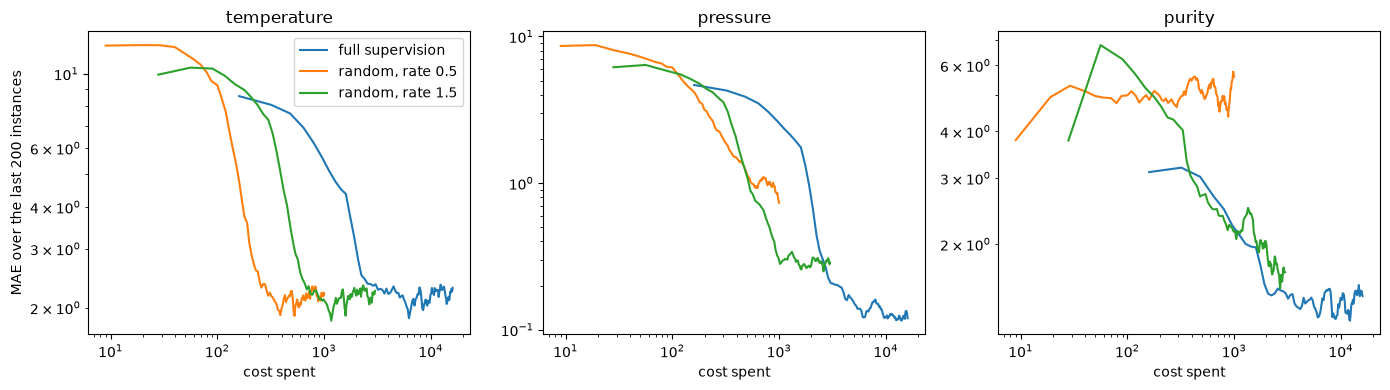

In [7]:
setups = {
    "full supervision": (fl.strategy.QueryAll(), fl.budget.Unlimited()),
    "random, rate 0.5": (fl.strategy.RandomPerOutput(p=0.5, seed=42), fl.budget.RateBudget(0.5)),
    "random, rate 1.5": (fl.strategy.RandomPerOutput(p=0.5, seed=42), fl.budget.RateBudget(1.5)),
}

curves = {}
for name, (strategy, budget) in setups.items():
    log = fl.evaluate.prequential(process_stream(2000), make_model(), strategy, budget, COSTS)
    curves[name] = fl.metrics.curve(log, utils.Rolling(metrics.MAE, window_size=200), every=20)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, output in zip(axes, OUTPUTS):
    for name, curve in curves.items():
        c = curve[curve["output"] == output]
        ax.plot(c["cum_cost"], c["value"], label=name)
    ax.set(title=output, xlabel="cost spent", xscale="log", yscale="log")
axes[0].set_ylabel("MAE over the last 200 instances")
axes[0].legend()
fig.tight_layout()

Each curve covers the same 2000 instances, but full supervision spends 8 cost units per
instance, so its curve extends much further to the right. Read the plot vertically to compare
setups at the same cost. Random querying is only a baseline: the point of fishladder is to make
this comparison easy for smarter strategies.

The plot also shows the greedy budget manager's bias at its worst. With a rate of 0.5, `purity` is
never queried at all in 2000 instances, because the cheap outputs always spend the budget before
5 cost units can build up. Its curve stays flat at the error of an untrained model. The next section shows how to avoid
this.

## Splitting the budget per output

`fl.budget.PerOutput` gives each output its own share of a budget, so that each output saves up
for its own queries and cannot be starved by the others. By default the budget is split equally.
Passing the costs as shares gives every output the same query rate instead.

In [8]:
import pandas as pd

budgets = {
    "shared": fl.budget.RateBudget(0.5),
    "per output, equal shares": fl.budget.PerOutput(fl.budget.RateBudget(0.5)),
    "per output, shares = costs": fl.budget.PerOutput(fl.budget.RateBudget(0.5), shares=COSTS),
}

queries = {}
curves = {}
for name, budget in budgets.items():
    strategy = fl.strategy.RandomPerOutput(p=0.5, seed=42)
    log = fl.evaluate.prequential(process_stream(2000), make_model(), strategy, budget, COSTS)
    queries[name] = log.to_frame().groupby("output")["queried"].sum()
    curves[name] = fl.metrics.curve(log, utils.Rolling(metrics.MAE, window_size=200), every=20)

pd.DataFrame(queries)

,shared,"per output, equal shares","per output, shares = costs"
output,,,
pressure,175,166,125
purity,0,66,125
temperature,650,333,125


All three setups spend the same 0.5 cost units per instance, but split them differently. With
per-output budgets, `purity` is queried regularly and its error goes down. The price is paid by
`temperature`, the cheapest output, which used to take most of the budget: it now reaches the same
error more slowly. Which split is right depends on how much each output matters to you.

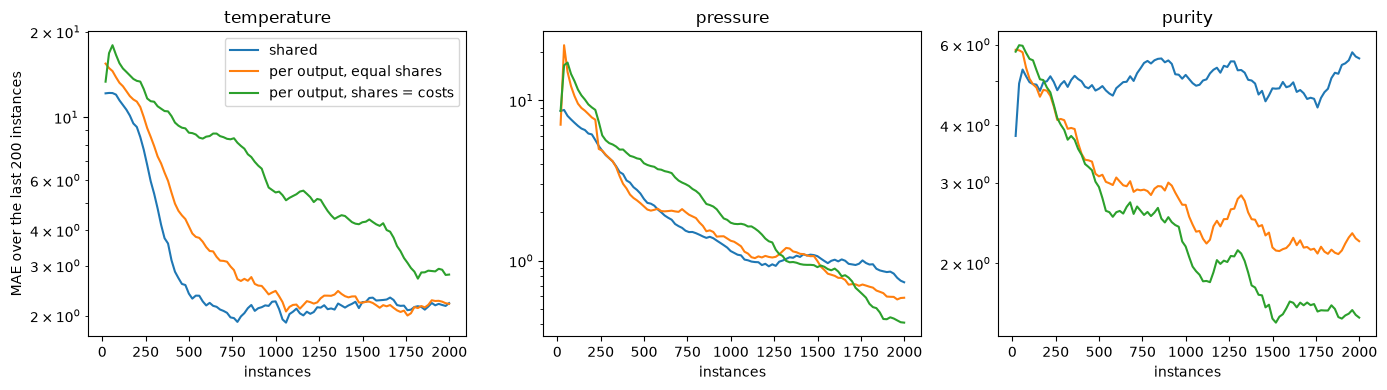

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, output in zip(axes, OUTPUTS):
    for name, curve in curves.items():
        c = curve[curve["output"] == output]
        ax.plot(c["step"], c["value"], label=name)
    ax.set(title=output, xlabel="instances", yscale="log")
axes[0].set_ylabel("MAE over the last 200 instances")
axes[0].legend()
fig.tight_layout()

Since the three setups spend at the same rate, the curves are drawn against the number of
instances here.

## Monitoring a run

`fl.evaluate.iter_prequential` is the counterpart of River's `evaluate.iter_progressive_val_score`:
it yields the state of the evaluation every `step` instances.

In [10]:
for state in fl.evaluate.iter_prequential(
    process_stream(2000),
    make_model(),
    fl.strategy.RandomPerOutput(p=0.3, seed=42),
    fl.budget.RateBudget(1.5),
    COSTS,
    metric=metrics.multioutput.MacroAverage(metrics.MAE()),
    step=500,
):
    print(state)

{'Step': 500, 'Queries': 340, 'Cost': 745.0, 'MacroAverage': MacroAverage(MAE): 3.434594}
{'Step': 1000, 'Queries': 681, 'Cost': 1495.0, 'MacroAverage': MacroAverage(MAE): 2.414994}
{'Step': 1500, 'Queries': 1036, 'Cost': 2247.0, 'MacroAverage': MacroAverage(MAE): 2.043582}
{'Step': 2000, 'Queries': 1367, 'Cost': 2999.0, 'MacroAverage': MacroAverage(MAE): 1.859892}


## Learning from unlabelled instances

The scaler in each pipeline does not need labels, yet by default it only learns from the instances
whose labels were queried, since that is when `learn_one` is called. With
`learn_unsupervised=True`, River pipelines update their unsupervised steps when predicting
instead, so the scalers learn from every instance. This matters most when labels are scarce, so
here each output only gets 0.1 cost units per instance.

A chain also predicts when it learns, so its scalers would learn twice from the instances it
learns from. We use one model per output instead, with `multioutput.PerOutputRegressor`.

In [11]:
def make_per_output_model():
    return multioutput.PerOutputRegressor(
        preprocessing.StandardScaler() | linear_model.LinearRegression()
    )


errors = {}
for learn_unsupervised in (False, True):
    log = fl.evaluate.prequential(
        process_stream(2000),
        make_per_output_model(),
        fl.strategy.RandomPerOutput(p=0.5, seed=42),
        fl.budget.PerOutput(fl.budget.RateBudget(0.1)),
        COSTS,
        learn_unsupervised=learn_unsupervised,
    )
    mae = fl.metrics.per_output(log, metrics.MAE())
    errors[f"MAE, learn_unsupervised={learn_unsupervised}"] = {o: m.get() for o, m in mae.items()}

queries = log.to_frame().groupby("output")["queried"].sum()
pd.DataFrame({"queries": queries, **errors})

,queries,"MAE, learn_unsupervised=False","MAE, learn_unsupervised=True"
pressure,33,5.423432,5.142614
purity,13,6.322182,4.541684
temperature,66,7.983079,8.078403


Random querying does not depend on the model, so both runs query the same instances. Without
`learn_unsupervised`, the scaler of `purity` only learns from the 13 instances it was queried
for, and `purity` gains the most from learning from all 2000 instances. `pressure` also improves,
while `temperature`, the output with the most labels, stays about the same.

Models and strategies that are not River pipelines can also learn from every instance, by
defining a `learn_unsupervised(x)` method: it is called with each instance before it is
predicted.